# UCF101 — BiLSTM + Temporal Attention on the Group-Aware Split

## Purpose

This is a **replacement training experiment** for the corrected dataset in `data/processed/sequences_group_split_v1/`.

It reuses your existing 51-feature, 16-frame pose sequences and trains a **two-layer Bidirectional LSTM with temporal attention**, matching the stronger architecture you previously tested. It does not run YOLO, ViTPose, pose extraction, or sequence building.

### What this notebook does

- Loads the existing group-aware train/validation/test arrays using memory maps.
- Checks source-video and recording-group separation.
- Keeps `BATCH_SIZE = 8` to respect your earlier memory limitation.
- Selects the best checkpoint using **validation video-level macro-F1** (the primary metric you want to improve), while also reporting window-level metrics.
- Saves a best checkpoint, recovery checkpoints every 5 epochs, and a CSV training history.
- Evaluates the selected checkpoint on the held-out test set once, reporting both window-level and video-level results.
- Reports missing test classes explicitly. Your current audit found no BreastStroke test windows, so its test-class F1 is not estimable.

### Safety

This notebook writes to a **new timestamped run folder** under `outputs/models/` and `outputs/reports/`. It does not overwrite your previous LSTM, BiLSTM, motion-aware, regularized, or sequence files.

Run every cell from top to bottom. If the data checks fail, stop and share the error rather than editing the split manually.

## 0. Imports, paths and experiment settings

In [1]:
from pathlib import Path
from datetime import datetime
import os
import gc
import json
import copy
import random
import logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

# ------------------------------------------------------------
# Project paths — change PROJECT_DIR only if your project moved.
# ------------------------------------------------------------
PROJECT_DIR = Path(r"C:\Users\admin\ViTPose_Action_Recognition")
SEQUENCE_DIR = PROJECT_DIR / "data" / "processed" / "sequences_group_split_v1"
OUTPUT_MODEL_ROOT = PROJECT_DIR / "outputs" / "models"
OUTPUT_REPORT_ROOT = PROJECT_DIR / "outputs" / "reports"

# Each run gets a new folder, so a rerun will not overwrite an earlier run.
RUN_ID = datetime.now().strftime("%Y%m%d_%H%M%S")
MODEL_RUN_DIR = OUTPUT_MODEL_ROOT / f"bilstm_attention_group_split_v1_{RUN_ID}"
REPORT_RUN_DIR = OUTPUT_REPORT_ROOT / f"bilstm_attention_group_split_v1_{RUN_ID}"
RECOVERY_DIR = MODEL_RUN_DIR / "recovery_checkpoints"

for folder in [MODEL_RUN_DIR, REPORT_RUN_DIR, RECOVERY_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Reproducibility and training settings.
# Match the stronger BiLSTM-attention experiment you ran earlier.
# Batch size remains 8 for your memory constraint.
# ------------------------------------------------------------
SEED = 42
BATCH_SIZE = 8
HIDDEN_SIZE = 128
NUM_LAYERS = 2
DROPOUT = 0.35
LEARNING_RATE = 5e-4
WEIGHT_DECAY = 1e-3
LABEL_SMOOTHING = 0.05
MAX_EPOCHS = 100
PATIENCE = 12
SAVE_EVERY = 5
NUM_WORKERS = 0

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True

print("Project:", PROJECT_DIR)
print("Group-aware sequence directory:", SEQUENCE_DIR)
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("Batch size:", BATCH_SIZE)
print("New model output:", MODEL_RUN_DIR)
print("New report output:", REPORT_RUN_DIR)

assert PROJECT_DIR.is_dir(), f"Project folder not found: {PROJECT_DIR}"
assert SEQUENCE_DIR.is_dir(), f"Group-aware sequence folder not found: {SEQUENCE_DIR}"


Project: C:\Users\admin\ViTPose_Action_Recognition
Group-aware sequence directory: C:\Users\admin\ViTPose_Action_Recognition\data\processed\sequences_group_split_v1
Device: cuda:0
GPU: NVIDIA RTX A4000
Batch size: 8
New model output: C:\Users\admin\ViTPose_Action_Recognition\outputs\models\bilstm_attention_group_split_v1_20261030_095320
New report output: C:\Users\admin\ViTPose_Action_Recognition\outputs\reports\bilstm_attention_group_split_v1_20261030_095320


## 1. Load the existing group-aware arrays

In [2]:
required_files = [
    "X_train.npy", "y_train.npy", "videos_train.npy",
    "X_val.npy", "y_val.npy", "videos_val.npy",
    "X_test.npy", "y_test.npy", "videos_test.npy",
    "label_map.json", "video_split_manifest.csv",
]
missing = [name for name in required_files if not (SEQUENCE_DIR / name).is_file()]
assert not missing, (
    f"Missing required files in {SEQUENCE_DIR}: {missing}. "
    "Run the group-aware sequence builder first."
)

# Read-only memory maps avoid loading all X arrays into RAM at once.
X_train = np.load(SEQUENCE_DIR / "X_train.npy", mmap_mode="r", allow_pickle=False)
y_train = np.load(SEQUENCE_DIR / "y_train.npy", mmap_mode="r", allow_pickle=False)
videos_train = np.load(SEQUENCE_DIR / "videos_train.npy", mmap_mode="r", allow_pickle=False)

X_val = np.load(SEQUENCE_DIR / "X_val.npy", mmap_mode="r", allow_pickle=False)
y_val = np.load(SEQUENCE_DIR / "y_val.npy", mmap_mode="r", allow_pickle=False)
videos_val = np.load(SEQUENCE_DIR / "videos_val.npy", mmap_mode="r", allow_pickle=False)

X_test = np.load(SEQUENCE_DIR / "X_test.npy", mmap_mode="r", allow_pickle=False)
y_test = np.load(SEQUENCE_DIR / "y_test.npy", mmap_mode="r", allow_pickle=False)
videos_test = np.load(SEQUENCE_DIR / "videos_test.npy", mmap_mode="r", allow_pickle=False)

label_map = json.loads((SEQUENCE_DIR / "label_map.json").read_text(encoding="utf-8"))
id_to_label = {int(k): str(v) for k, v in label_map.items()}
class_ids = sorted(id_to_label)
class_names = [id_to_label[i] for i in class_ids]
NUM_CLASSES = len(class_ids)
INPUT_SIZE = int(X_train.shape[2])
SEQUENCE_LENGTH = int(X_train.shape[1])

print("Classes:", NUM_CLASSES)
print("Sequence length:", SEQUENCE_LENGTH)
print("Features per frame:", INPUT_SIZE)
print("Train:", X_train.shape, "| windows:", len(y_train), "| videos:", len(np.unique(videos_train)))
print("Validation:", X_val.shape, "| windows:", len(y_val), "| videos:", len(np.unique(videos_val)))
print("Test:", X_test.shape, "| windows:", len(y_test), "| videos:", len(np.unique(videos_test)))


Classes: 101
Sequence length: 16
Features per frame: 51
Train: (61747, 16, 51) | windows: 61747 | videos: 7236
Validation: (21815, 16, 51) | windows: 21815 | videos: 2454
Test: (21960, 16, 51) | windows: 21960 | videos: 2435


## 2. Validate dimensions, labels and recording-group separation

In [3]:
# Shape checks.
assert X_train.ndim == X_val.ndim == X_test.ndim == 3
assert X_train.shape[1:] == X_val.shape[1:] == X_test.shape[1:]
assert INPUT_SIZE == 51, f"Expected 51 features (17 joints x/y/confidence), got {INPUT_SIZE}"
assert len(X_train) == len(y_train) == len(videos_train)
assert len(X_val) == len(y_val) == len(videos_val)
assert len(X_test) == len(y_test) == len(videos_test)
assert len(X_train) > 0 and len(X_val) > 0 and len(X_test) > 0

# Label IDs must be contiguous and valid.
assert class_ids == list(range(NUM_CLASSES)), f"Non-contiguous class IDs: {class_ids}"
for split_name, y in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    observed = set(np.unique(np.asarray(y, dtype=np.int64)).tolist())
    invalid = observed - set(class_ids)
    assert not invalid, f"Invalid class IDs in {split_name}: {invalid}"
    missing_classes = [id_to_label[i] for i in class_ids if i not in observed]
    print(f"{split_name}: {len(observed)}/{NUM_CLASSES} classes represented")
    if missing_classes:
        print("  Classes without windows:", missing_classes)

# Source-video IDs must be unique to one split.
video_sets = {
    "train": set(np.unique(videos_train).tolist()),
    "val": set(np.unique(videos_val).tolist()),
    "test": set(np.unique(videos_test).tolist()),
}
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    overlap = video_sets[a] & video_sets[b]
    assert not overlap, f"Source-video leakage between {a} and {b}: {list(overlap)[:5]}"

# Recording-group isolation check from the exact manifest used by the builder.
split_manifest = pd.read_csv(SEQUENCE_DIR / "video_split_manifest.csv")
required_manifest_cols = {"recording_group_key", "split"}
assert required_manifest_cols.issubset(split_manifest.columns), (
    f"Manifest must contain {required_manifest_cols}"
)
group_split_counts = split_manifest.groupby("recording_group_key")["split"].nunique()
leaked_groups = group_split_counts[group_split_counts > 1]
assert leaked_groups.empty, (
    "Recording-group overlap detected: " + str(leaked_groups.index[:10].tolist())
)

unparsed_count = 0
if "group_parsed_from_filename" in split_manifest.columns:
    unparsed_count = int((~split_manifest["group_parsed_from_filename"].astype(bool)).sum())

train_counts = np.bincount(np.asarray(y_train, dtype=np.int64), minlength=NUM_CLASSES)
missing_train = [id_to_label[i] for i, count in enumerate(train_counts) if count == 0]
assert not missing_train, f"No training windows for classes: {missing_train}"

print("\nPASS: no source-video leakage and no recording-group-key overlap.")
print("Unparsed recording-group filenames in manifest:", unparsed_count)
print("Sequence length:", SEQUENCE_LENGTH, "| features/frame:", INPUT_SIZE)
print("NOTE: this is a randomized group-aware split, not an official UCF101 split-list evaluation.")


train: 101/101 classes represented
validation: 101/101 classes represented
test: 100/101 classes represented
  Classes without windows: ['BreastStroke']

PASS: no source-video leakage and no recording-group-key overlap.
Unparsed recording-group filenames in manifest: 0
Sequence length: 16 | features/frame: 51
NOTE: this is a randomized group-aware split, not an official UCF101 split-list evaluation.


## 3. Check class support before training

In [4]:
support_rows = []
for class_id in class_ids:
    row = {"class_id": class_id, "label": id_to_label[class_id]}
    for split_name, y in [("train", y_train), ("val", y_val), ("test", y_test)]:
        row[f"{split_name}_windows"] = int(np.sum(np.asarray(y) == class_id))
    support_rows.append(row)

support_df = pd.DataFrame(support_rows)
support_path = REPORT_RUN_DIR / "class_support_by_split.csv"
support_df.to_csv(support_path, index=False)
print("Classes with zero test windows:", support_df.loc[support_df["test_windows"] == 0, "label"].tolist())
print("Classes with fewer than 10 test windows:")
print(support_df.loc[support_df["test_windows"] < 10, ["label", "test_windows"]].to_string(index=False))
print("Saved class support table:", support_path)
print("\nFirst 12 classes by smallest test support:")
print(support_df.sort_values("test_windows").head(12).to_string(index=False))

# Class weighting: square-root inverse frequency, normalized to mean 1.
# This is less extreme than full inverse-frequency weighting.
class_weights = 1.0 / np.sqrt(train_counts.astype(np.float64))
class_weights = class_weights / class_weights.mean()
class_weights_t = torch.tensor(class_weights, dtype=torch.float32, device=DEVICE)


Classes with zero test windows: ['BreastStroke']
Classes with fewer than 10 test windows:
       label  test_windows
BreastStroke             0
Saved class support table: C:\Users\admin\ViTPose_Action_Recognition\outputs\reports\bilstm_attention_group_split_v1_20261030_095320\class_support_by_split.csv

First 12 classes by smallest test support:
 class_id             label  train_windows  val_windows  test_windows
       18      BreastStroke             19            4             0
       21       CliffDiving             65           21            11
       71           PushUps             97           38            26
       92       ThrowDiscus            257           99            48
        8    BasketballDunk            149           62            57
       88             Swing            400           75            65
       96 VolleyballSpiking            317          109            73
       47       JumpingJack            177           73            74
       31        Front

## 4. Data loaders — batch size 8

In [5]:
class PoseSequenceDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        # Copy only one sequence from the read-only memory map.
        x = np.array(self.X[idx], dtype=np.float32, copy=True)
        y = int(self.y[idx])
        return torch.from_numpy(x), torch.tensor(y, dtype=torch.long)

train_dataset = PoseSequenceDataset(X_train, y_train)
val_dataset = PoseSequenceDataset(X_val, y_val)
test_dataset = PoseSequenceDataset(X_test, y_test)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda")
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda")
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda")
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))
print("Batch size:", BATCH_SIZE)


Train batches: 7719
Validation batches: 2727
Test batches: 2745
Batch size: 8


## 5. Define the BiLSTM with temporal attention

In [6]:
class PoseBiLSTMAttention(nn.Module):
    """Two-direction LSTM with learned temporal attention pooling."""
    def __init__(self, input_size, hidden_size, num_layers, num_classes, dropout):
        super().__init__()
        self.input_norm = nn.LayerNorm(input_size)
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        self.attention = nn.Sequential(
            nn.Linear(hidden_size * 2, hidden_size),
            nn.Tanh(),
            nn.Linear(hidden_size, 1),
        )
        self.classifier = nn.Sequential(
            nn.LayerNorm(hidden_size * 2),
            nn.Dropout(dropout),
            nn.Linear(hidden_size * 2, num_classes),
        )

    def forward(self, x):
        x = self.input_norm(x)
        sequence_output, _ = self.lstm(x)
        attention_scores = self.attention(sequence_output).squeeze(-1)
        attention_weights = torch.softmax(attention_scores, dim=1)
        context = torch.sum(sequence_output * attention_weights.unsqueeze(-1), dim=1)
        return self.classifier(context)

model = PoseBiLSTMAttention(
    input_size=INPUT_SIZE,
    hidden_size=HIDDEN_SIZE,
    num_layers=NUM_LAYERS,
    num_classes=NUM_CLASSES,
    dropout=DROPOUT,
).to(DEVICE)

criterion = nn.CrossEntropyLoss(
    weight=class_weights_t,
    label_smoothing=LABEL_SMOOTHING,
)
optimizer = torch.optim.AdamW(
    model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=3, min_lr=1e-6
)

print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))


PoseBiLSTMAttention(
  (input_norm): LayerNorm((51,), eps=1e-05, elementwise_affine=True)
  (lstm): LSTM(51, 128, num_layers=2, batch_first=True, dropout=0.35, bidirectional=True)
  (attention): Sequential(
    (0): Linear(in_features=256, out_features=128, bias=True)
    (1): Tanh()
    (2): Linear(in_features=128, out_features=1, bias=True)
  )
  (classifier): Sequential(
    (0): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
    (1): Dropout(p=0.35, inplace=False)
    (2): Linear(in_features=256, out_features=101, bias=True)
  )
)
Trainable parameters: 640204


## 6. Training and validation helpers

In [7]:
def classification_metrics(y_true, y_pred, labels):
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(
            y_true, y_pred, labels=labels, average="macro", zero_division=0
        )),
    }


def aggregate_video_probabilities(probabilities, y_true, video_ids, labels):
    """Average window probabilities per source video and verify one label/video."""
    probabilities = np.asarray(probabilities, dtype=np.float32)
    y_true = np.asarray(y_true, dtype=np.int64)
    video_ids = np.asarray(video_ids)

    assert len(probabilities) == len(y_true) == len(video_ids)
    unique_videos, inverse = np.unique(video_ids, return_inverse=True)
    n_videos = len(unique_videos)
    n_classes = probabilities.shape[1]

    probability_sums = np.zeros((n_videos, n_classes), dtype=np.float64)
    np.add.at(probability_sums, inverse, probabilities)
    window_counts = np.bincount(inverse, minlength=n_videos)
    video_probabilities = probability_sums / window_counts[:, None]

    video_true = np.empty(n_videos, dtype=np.int64)
    for i in range(n_videos):
        labels_for_video = np.unique(y_true[inverse == i])
        if len(labels_for_video) != 1:
            raise ValueError(
                f"Source video {unique_videos[i]!r} has inconsistent labels: {labels_for_video}"
            )
        video_true[i] = labels_for_video[0]

    video_pred = video_probabilities.argmax(axis=1)
    return unique_videos, video_true, video_pred, video_probabilities, window_counts


def run_epoch(model, loader, training, collect_probabilities=False):
    model.train(training)
    total_loss = 0.0
    total_count = 0
    true_chunks, pred_chunks, probability_chunks = [], [], []

    context = torch.enable_grad if training else torch.inference_mode
    with context():
        for xb, yb in loader:
            xb = xb.to(DEVICE, non_blocking=(DEVICE.type == "cuda"))
            yb = yb.to(DEVICE, non_blocking=(DEVICE.type == "cuda"))

            if training:
                optimizer.zero_grad(set_to_none=True)

            logits = model(xb)
            loss = criterion(logits, yb)

            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()

            batch_size = len(yb)
            total_loss += float(loss.item()) * batch_size
            total_count += batch_size
            true_chunks.append(yb.detach().cpu().numpy())
            pred_chunks.append(logits.detach().argmax(dim=1).cpu().numpy())

            if collect_probabilities:
                probability_chunks.append(torch.softmax(logits.detach(), dim=1).cpu().numpy())

    y_true_epoch = np.concatenate(true_chunks)
    y_pred_epoch = np.concatenate(pred_chunks)
    metrics = classification_metrics(y_true_epoch, y_pred_epoch, class_ids)
    metrics["loss"] = total_loss / max(total_count, 1)

    if collect_probabilities:
        metrics["probabilities"] = np.concatenate(probability_chunks)
        metrics["y_true"] = y_true_epoch

    return metrics

print("Training helpers ready.")


Training helpers ready.


## 7. Train and select by validation video-level macro-F1

The validation pass also aggregates predictions by `videos_val`. The best checkpoint is selected using **validation video-level macro-F1**, which aligns model selection with your video-level action-recognition goal. Window-level validation metrics are still logged for comparison.

In [8]:
MODEL_PATH = MODEL_RUN_DIR / "bilstm_attention_group_split_v1_best.pt"
HISTORY_PATH = REPORT_RUN_DIR / "bilstm_attention_group_split_v1_training_history.csv"
LOG_PATH = REPORT_RUN_DIR / "bilstm_attention_group_split_v1_training.log"

logger = logging.getLogger(f"bilstm_group_split_{RUN_ID}")
logger.setLevel(logging.INFO)
logger.handlers.clear()
logger.propagate = False
file_handler = logging.FileHandler(LOG_PATH, encoding="utf-8")
file_handler.setFormatter(logging.Formatter("%(asctime)s | %(levelname)s | %(message)s"))
logger.addHandler(file_handler)


def atomic_torch_save(payload, target_path):
    target_path = Path(target_path)
    temp_path = target_path.with_name(target_path.name + ".tmp")
    torch.save(payload, temp_path)
    os.replace(temp_path, target_path)


history = []
best_val_video_f1 = -1.0
best_val_video_accuracy = -1.0
best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0

logger.info("Run=%s | device=%s | batch=%d | classes=%d", RUN_ID, DEVICE, BATCH_SIZE, NUM_CLASSES)
logger.info("Train windows=%d | val windows=%d | test windows=%d", len(y_train), len(y_val), len(y_test))

for epoch in range(1, MAX_EPOCHS + 1):
    train_m = run_epoch(model, train_loader, training=True, collect_probabilities=False)
    val_m = run_epoch(model, val_loader, training=False, collect_probabilities=True)

    # Validation video-level aggregation is computed each epoch for checkpoint selection.
    (val_video_ids, val_video_true, val_video_pred,
     val_video_probs, val_video_counts) = aggregate_video_probabilities(
        val_m["probabilities"], val_m["y_true"], videos_val, class_ids
    )
    val_video_m = classification_metrics(val_video_true, val_video_pred, class_ids)
    val_loss = float(val_m["loss"])
    scheduler.step(val_loss)
    current_lr = float(optimizer.param_groups[0]["lr"])

    row = {
        "epoch": epoch,
        "learning_rate": current_lr,
        "train_loss": train_m["loss"],
        "train_window_accuracy": train_m["accuracy"],
        "train_window_macro_f1": train_m["macro_f1"],
        "train_window_balanced_accuracy": train_m["balanced_accuracy"],
        "val_loss": val_loss,
        "val_window_accuracy": val_m["accuracy"],
        "val_window_macro_f1": val_m["macro_f1"],
        "val_window_balanced_accuracy": val_m["balanced_accuracy"],
        "val_video_accuracy": val_video_m["accuracy"],
        "val_video_balanced_accuracy": val_video_m["balanced_accuracy"],
        "val_video_macro_f1": val_video_m["macro_f1"],
    }
    history.append(row)
    pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)

    message = (
        f"Epoch {epoch:03d}/{MAX_EPOCHS} | lr={current_lr:.2e} | "
        f"train acc={train_m['accuracy']:.3f}, F1={train_m['macro_f1']:.3f} | "
        f"val-window acc={val_m['accuracy']:.3f}, F1={val_m['macro_f1']:.3f} | "
        f"val-VIDEO acc={val_video_m['accuracy']:.3f}, "
        f"macro-F1={val_video_m['macro_f1']:.3f}"
    )
    print(message, flush=True)
    logger.info(message)

    # Primary model-selection criterion: validation video-level macro-F1.
    improved = (
        val_video_m["macro_f1"] > best_val_video_f1 + 1e-6
        or (
            abs(val_video_m["macro_f1"] - best_val_video_f1) <= 1e-6
            and val_video_m["accuracy"] > best_val_video_accuracy + 1e-6
        )
        or (
            abs(val_video_m["macro_f1"] - best_val_video_f1) <= 1e-6
            and abs(val_video_m["accuracy"] - best_val_video_accuracy) <= 1e-6
            and val_loss < best_val_loss
        )
    )

    if improved:
        best_val_video_f1 = float(val_video_m["macro_f1"])
        best_val_video_accuracy = float(val_video_m["accuracy"])
        best_val_loss = val_loss
        best_epoch = epoch
        epochs_without_improvement = 0

        best_payload = {
            "model_state": copy.deepcopy(model.state_dict()),
            "input_size": INPUT_SIZE,
            "sequence_length": SEQUENCE_LENGTH,
            "hidden_size": HIDDEN_SIZE,
            "num_layers": NUM_LAYERS,
            "dropout": DROPOUT,
            "num_classes": NUM_CLASSES,
            "label_map": label_map,
            "best_epoch": best_epoch,
            "best_val_video_macro_f1": best_val_video_f1,
            "best_val_video_accuracy": best_val_video_accuracy,
            "best_val_loss": best_val_loss,
            "architecture": "bidirectional_lstm_temporal_attention",
            "split_directory": str(SEQUENCE_DIR),
            "run_id": RUN_ID,
            "seed": SEED,
        }
        atomic_torch_save(best_payload, MODEL_PATH)
        print("  Saved best validation-video checkpoint:", MODEL_PATH.name, flush=True)
        logger.info("Saved best checkpoint at epoch %d", epoch)
    else:
        epochs_without_improvement += 1

    # Recovery checkpoint every five epochs; separate from the best model.
    if epoch % SAVE_EVERY == 0:
        recovery_path = RECOVERY_DIR / f"recovery_epoch_{epoch:03d}.pt"
        recovery_payload = {
            "epoch": epoch,
            "model_state": model.state_dict(),
            "optimizer_state": optimizer.state_dict(),
            "scheduler_state": scheduler.state_dict(),
            "history": history,
            "best_epoch": best_epoch,
            "best_val_video_macro_f1": best_val_video_f1,
            "best_val_video_accuracy": best_val_video_accuracy,
            "best_val_loss": best_val_loss,
            "epochs_without_improvement": epochs_without_improvement,
            "run_id": RUN_ID,
        }
        atomic_torch_save(recovery_payload, recovery_path)
        logger.info("Saved recovery checkpoint %s", recovery_path.name)

    del val_m, val_video_probs
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    gc.collect()

    if epochs_without_improvement >= PATIENCE:
        stop_message = (
            f"Early stopping at epoch {epoch}; best epoch={best_epoch}; "
            f"best validation video macro-F1={best_val_video_f1:.4f}"
        )
        print(stop_message)
        logger.info(stop_message)
        break

assert MODEL_PATH.is_file(), "No best checkpoint was saved."
print("\nTraining complete.")
print("Best epoch:", best_epoch)
print("Best validation video macro-F1:", round(best_val_video_f1, 4))
print("Best validation video accuracy:", round(best_val_video_accuracy, 4))
print("Best model:", MODEL_PATH.resolve())
print("Training history:", HISTORY_PATH.resolve())
print("Training log:", LOG_PATH.resolve())
print("Recovery checkpoints:", RECOVERY_DIR.resolve())


Epoch 001/100 | lr=5.00e-04 | train acc=0.518, F1=0.418 | val-window acc=0.398, F1=0.316 | val-VIDEO acc=0.397, macro-F1=0.357
  Saved best validation-video checkpoint: bilstm_attention_group_split_v1_best.pt
Epoch 002/100 | lr=5.00e-04 | train acc=0.728, F1=0.651 | val-window acc=0.424, F1=0.353 | val-VIDEO acc=0.446, macro-F1=0.406
  Saved best validation-video checkpoint: bilstm_attention_group_split_v1_best.pt
Epoch 003/100 | lr=5.00e-04 | train acc=0.815, F1=0.758 | val-window acc=0.433, F1=0.365 | val-VIDEO acc=0.472, macro-F1=0.436
  Saved best validation-video checkpoint: bilstm_attention_group_split_v1_best.pt
Epoch 004/100 | lr=5.00e-04 | train acc=0.869, F1=0.825 | val-window acc=0.434, F1=0.375 | val-VIDEO acc=0.479, macro-F1=0.449
  Saved best validation-video checkpoint: bilstm_attention_group_split_v1_best.pt
Epoch 005/100 | lr=2.50e-04 | train acc=0.904, F1=0.871 | val-window acc=0.429, F1=0.369 | val-VIDEO acc=0.479, macro-F1=0.445
Epoch 006/100 | lr=2.50e-04 | train a

## 8. Plot compact learning curves

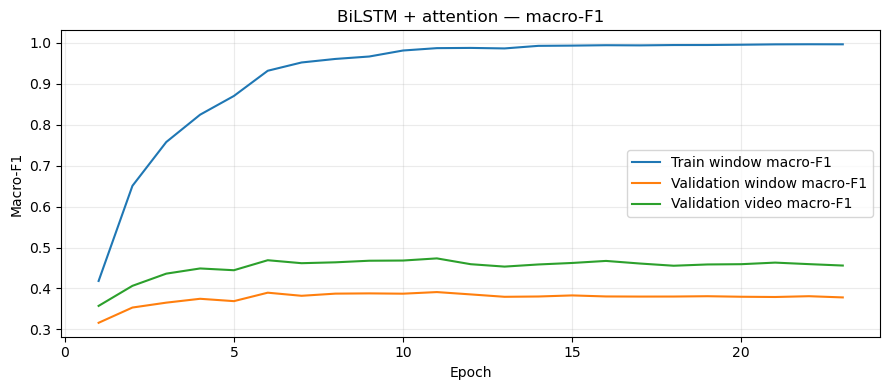

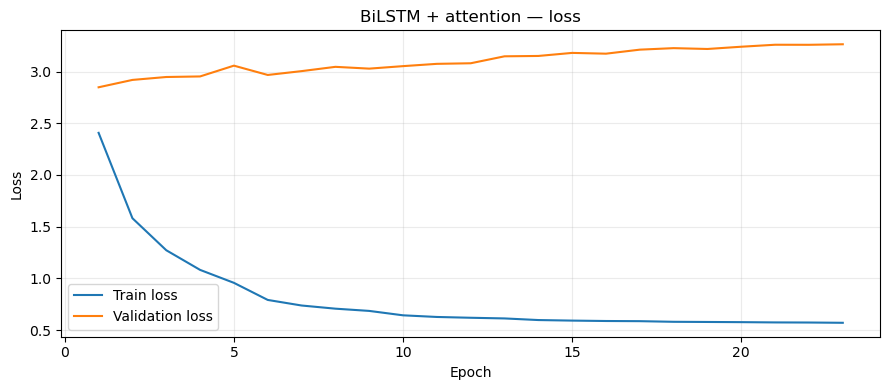

Plots saved in: C:\Users\admin\ViTPose_Action_Recognition\outputs\reports\bilstm_attention_group_split_v1_20261030_095320


In [10]:
history_df = pd.read_csv(HISTORY_PATH)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(history_df["epoch"], history_df["train_window_macro_f1"], label="Train window macro-F1")
ax.plot(history_df["epoch"], history_df["val_window_macro_f1"], label="Validation window macro-F1")
ax.plot(history_df["epoch"], history_df["val_video_macro_f1"], label="Validation video macro-F1")
ax.set_xlabel("Epoch")
ax.set_ylabel("Macro-F1")
ax.set_title("BiLSTM + attention — macro-F1")
ax.legend()
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.savefig(REPORT_RUN_DIR / "training_macro_f1.png", dpi=140)
plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(history_df["epoch"], history_df["train_loss"], label="Train loss")
ax.plot(history_df["epoch"], history_df["val_loss"], label="Validation loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_title("BiLSTM + attention — loss")
ax.legend()
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.savefig(REPORT_RUN_DIR / "training_loss.png", dpi=140)
plt.show()

print("Plots saved in:", REPORT_RUN_DIR)


## 9. Final held-out test evaluation

This evaluates the best checkpoint selected using validation video-level macro-F1. It reports both window-level and video-level metrics. It also reports macro-F1 over all 101 classes **and** over classes that actually have test support, because the current split has zero BreastStroke test windows.

In [11]:
# Load only the best model checkpoint, not the last epoch or recovery checkpoint.
try:
    checkpoint = torch.load(MODEL_PATH, map_location=DEVICE, weights_only=True)
except TypeError:
    checkpoint = torch.load(MODEL_PATH, map_location=DEVICE)

best_model = PoseBiLSTMAttention(
    input_size=int(checkpoint["input_size"]),
    hidden_size=int(checkpoint["hidden_size"]),
    num_layers=int(checkpoint["num_layers"]),
    num_classes=int(checkpoint["num_classes"]),
    dropout=float(checkpoint["dropout"]),
).to(DEVICE)
best_model.load_state_dict(checkpoint["model_state"], strict=True)
best_model.eval()

# Predict probabilities for each test window.
test_probability_chunks = []
test_true_chunks = []
with torch.inference_mode():
    for xb, yb in test_loader:
        xb = xb.to(DEVICE, non_blocking=(DEVICE.type == "cuda"))
        logits = best_model(xb)
        test_probability_chunks.append(torch.softmax(logits, dim=1).cpu().numpy())
        test_true_chunks.append(yb.numpy())

window_probabilities = np.concatenate(test_probability_chunks, axis=0)
y_test_true = np.concatenate(test_true_chunks).astype(np.int64)
y_test_pred = window_probabilities.argmax(axis=1)

# Window-level metrics.
window_present_classes = sorted(np.unique(y_test_true).tolist())
window_metrics_all = classification_metrics(y_test_true, y_test_pred, class_ids)
window_metrics_supported = f1_score(
    y_test_true, y_test_pred,
    labels=window_present_classes,
    average="macro", zero_division=0
)

# Aggregate predictions per original source video.
(unique_test_videos, video_y_true, video_y_pred,
 video_probabilities, test_window_counts) = aggregate_video_probabilities(
    window_probabilities, y_test_true, videos_test, class_ids
)
video_present_classes = sorted(np.unique(video_y_true).tolist())
video_metrics_all = classification_metrics(video_y_true, video_y_pred, class_ids)
video_metrics_supported = f1_score(
    video_y_true, video_y_pred,
    labels=video_present_classes,
    average="macro", zero_division=0
)

missing_test_class_names = [
    id_to_label[i] for i in class_ids if i not in set(window_present_classes)
]

metrics = {
    "experiment": "BiLSTM + temporal attention on group-aware randomized split",
    "run_id": RUN_ID,
    "checkpoint": str(MODEL_PATH),
    "best_epoch": int(checkpoint["best_epoch"]),
    "best_validation_video_macro_f1": float(checkpoint["best_val_video_macro_f1"]),
    "best_validation_video_accuracy": float(checkpoint["best_val_video_accuracy"]),
    "num_classes_in_label_map": int(NUM_CLASSES),
    "classes_with_test_support": int(len(video_present_classes)),
    "classes_without_test_support": missing_test_class_names,
    "test_windows": int(len(y_test_true)),
    "test_source_videos": int(len(unique_test_videos)),
    "window_level_accuracy": float(window_metrics_all["accuracy"]),
    "window_level_balanced_accuracy_observed_classes": float(window_metrics_all["balanced_accuracy"]),
    "window_level_macro_f1_all_101_classes_zero_support_as_zero": float(window_metrics_all["macro_f1"]),
    "window_level_macro_f1_supported_classes_only": float(window_metrics_supported),
    "video_level_accuracy": float(video_metrics_all["accuracy"]),
    "video_level_balanced_accuracy_observed_classes": float(video_metrics_all["balanced_accuracy"]),
    "video_level_macro_f1_all_101_classes_zero_support_as_zero": float(video_metrics_all["macro_f1"]),
    "video_level_macro_f1_supported_classes_only": float(video_metrics_supported),
}

metrics_path = REPORT_RUN_DIR / "bilstm_attention_group_split_v1_test_metrics.json"
metrics_path.write_text(json.dumps(metrics, indent=2), encoding="utf-8")

# Per-video predictions.
per_video_df = pd.DataFrame({
    "video_id": np.asarray(unique_test_videos).astype(str),
    "true_class_id": video_y_true,
    "true_label": [id_to_label[int(i)] for i in video_y_true],
    "predicted_class_id": video_y_pred,
    "predicted_label": [id_to_label[int(i)] for i in video_y_pred],
    "number_of_windows": test_window_counts,
    "correct": video_y_true == video_y_pred,
    "mean_max_probability": video_probabilities.max(axis=1),
})
per_video_path = REPORT_RUN_DIR / "video_level_predictions.csv"
per_video_df.to_csv(per_video_path, index=False)

# Classification reports with all 101 labels explicitly included.
window_report = classification_report(
    y_test_true, y_test_pred,
    labels=class_ids,
    target_names=class_names,
    output_dict=True,
    zero_division=0,
)
video_report = classification_report(
    video_y_true, video_y_pred,
    labels=class_ids,
    target_names=class_names,
    output_dict=True,
    zero_division=0,
)
window_report_path = REPORT_RUN_DIR / "window_level_classification_report.csv"
video_report_path = REPORT_RUN_DIR / "video_level_classification_report.csv"
pd.DataFrame(window_report).transpose().to_csv(window_report_path)
pd.DataFrame(video_report).transpose().to_csv(video_report_path)

# Confusion matrix saved as CSV; avoid rendering a huge 101x101 matrix inline.
cm = confusion_matrix(y_test_true, y_test_pred, labels=class_ids)
cm_df = pd.DataFrame(cm, index=class_names, columns=class_names)
cm_path = REPORT_RUN_DIR / "window_level_confusion_matrix.csv"
cm_df.to_csv(cm_path)

print(json.dumps(metrics, indent=2))
print("\nSaved metrics:", metrics_path)
print("Saved per-video predictions:", per_video_path)
print("Saved window report:", window_report_path)
print("Saved video report:", video_report_path)
print("Saved confusion matrix CSV:", cm_path)


C:\Users\admin\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:2524: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


{
  "experiment": "BiLSTM + temporal attention on group-aware randomized split",
  "run_id": "20261030_095320",
  "checkpoint": "C:\\Users\\admin\\ViTPose_Action_Recognition\\outputs\\models\\bilstm_attention_group_split_v1_20261030_095320\\bilstm_attention_group_split_v1_best.pt",
  "best_epoch": 11,
  "best_validation_video_macro_f1": 0.4735249630690018,
  "best_validation_video_accuracy": 0.5069274653626732,
  "num_classes_in_label_map": 101,
  "classes_with_test_support": 100,
  "classes_without_test_support": [
    "BreastStroke"
  ],
  "test_windows": 21960,
  "test_source_videos": 2435,
  "window_level_accuracy": 0.4714025500910747,
  "window_level_balanced_accuracy_observed_classes": 0.4331052874206021,
  "window_level_macro_f1_all_101_classes_zero_support_as_zero": 0.41710552330431605,
  "window_level_macro_f1_supported_classes_only": 0.42127657853735917,
  "video_level_accuracy": 0.5055441478439425,
  "video_level_balanced_accuracy_observed_classes": 0.4881367707307435,
  "vi

## 10. Interpretation and experiment record

- Compare **video-level accuracy with video-level accuracy** and **video-level macro-F1 with video-level macro-F1**. Do not compare window and video metrics as if they were the same measure.
- The previous 70.18% video-level score came from the old random-video split. It is not directly comparable with this recording-group-aware test score.
- `BreastStroke` currently has zero test windows. The report therefore provides both all-101-class macro-F1 (zero-support class contributes zero) and supported-class macro-F1. The missing class should be documented; do not move its recording group into another split merely to force test support.
- The split is randomized and group-aware, **not an official UCF101 split-list benchmark**. For a paper-comparable result, later evaluate official split lists.
- This run trains a fresh model. It does not fine-tune or overwrite your earlier checkpoint.
- If validation video macro-F1 remains low while training macro-F1 rises, the next task is pose/data-quality investigation, not simply adding epochs.

### Files created by this run

- Best model: `outputs/models/<timestamped-run>/bilstm_attention_group_split_v1_best.pt`
- Recovery checkpoints: `outputs/models/<timestamped-run>/recovery_checkpoints/`
- Training history and logs: `outputs/reports/<timestamped-run>/`
- Test metrics and prediction CSVs: `outputs/reports/<timestamped-run>/`
